In [2]:

import pandas as pd
import zipfile
import urllib.request
import io

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"

response = urllib.request.urlopen(url)
zip_file = zipfile.ZipFile(io.BytesIO(response.read()))

df = pd.read_csv(
    zip_file.open("SMSSpamCollection"),
    sep="\t",
    header=None,
    names=["label", "message"]
)

print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nSpam and Ham Count:")
print(df["label"].value_counts())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset Shape:
(5572, 2)

Spam and Ham Count:
label
ham     4825
spam     747
Name: count, dtype: int64


In [3]:
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

print("Preprocessing libraries loaded successfully!")

Preprocessing libraries loaded successfully!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [4]:
def preprocess_text(text):

    text = text.lower()

    text = re.sub(r'[^a-z\s]', '', text)

    words = text.split()

    words = [
        stemmer.stem(word)
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)


df["clean_message"] = df["message"].apply(preprocess_text)

print("Original Message:")
print(df["message"][0])

print("\nPreprocessed Message:")
print(df["clean_message"][0])

Original Message:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Preprocessed Message:
go jurong point crazi avail bugi n great world la e buffet cine got amor wat


In [5]:
print(df[["label", "message", "clean_message"]].head(10))

  label                                            message  \
0   ham  Go until jurong point, crazy.. Available only ...   
1   ham                      Ok lar... Joking wif u oni...   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...   
3   ham  U dun say so early hor... U c already then say...   
4   ham  Nah I don't think he goes to usf, he lives aro...   
5  spam  FreeMsg Hey there darling it's been 3 week's n...   
6   ham  Even my brother is not like to speak with me. ...   
7   ham  As per your request 'Melle Melle (Oru Minnamin...   
8  spam  WINNER!! As a valued network customer you have...   
9  spam  Had your mobile 11 months or more? U R entitle...   

                                       clean_message  
0  go jurong point crazi avail bugi n great world...  
1                              ok lar joke wif u oni  
2  free entri wkli comp win fa cup final tkt st m...  
3                u dun say earli hor u c alreadi say  
4          nah dont think goe usf live aro

In [4]:
import pandas as pd
import zipfile
import urllib.request
import io

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"

response = urllib.request.urlopen(url)
zip_file = zipfile.ZipFile(io.BytesIO(response.read()))

df = pd.read_csv(
    zip_file.open("SMSSpamCollection"),
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(5572, 2)


In [6]:
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    words = text.split()

    words = [
        stemmer.stem(word)
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)

df["clean_message"] = df["message"].apply(preprocess_text)

print("Text preprocessing completed!")
print(df[["label", "clean_message"]].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Text preprocessing completed!
  label                                      clean_message
0   ham  go jurong point crazi avail bugi n great world...
1   ham                              ok lar joke wif u oni
2  spam  free entri wkli comp win fa cup final tkt st m...
3   ham                u dun say earli hor u c alreadi say
4   ham          nah dont think goe usf live around though


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X = df["clean_message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

vectorizer = TfidfVectorizer()

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("TF-IDF conversion completed successfully!")
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

TF-IDF conversion completed successfully!
Training matrix shape: (4457, 6273)
Testing matrix shape: (1115, 6273)


In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd
import time

# Create 4 ML models
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": LinearSVC(),
    "Naive Bayes": MultinomialNB()
}

results = []
predictions = {}

# Train and evaluate each model
for name, model in models.items():

    start = time.time()

    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    end = time.time()

    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="spam"
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="spam"
        ),
        "F1 Score": f1_score(
            y_test, y_pred, pos_label="spam"
        ),
        "Training Time": round(end - start, 3)
    })

# Display comparison table
results_df = pd.DataFrame(results)

print("MODEL COMPARISON RESULTS")
print("=" * 60)

print(results_df.round(4))

MODEL COMPARISON RESULTS
           Model  Accuracy  Precision  Recall  F1 Score  Training Time
0  Decision Tree    0.9516     0.8322  0.7987    0.8151          0.962
1            KNN    0.9166     1.0000  0.3758    0.5463          0.129
2            SVM    0.9821     0.9778  0.8859    0.9296          0.013
3    Naive Bayes    0.9641     1.0000  0.7315    0.8450          0.011


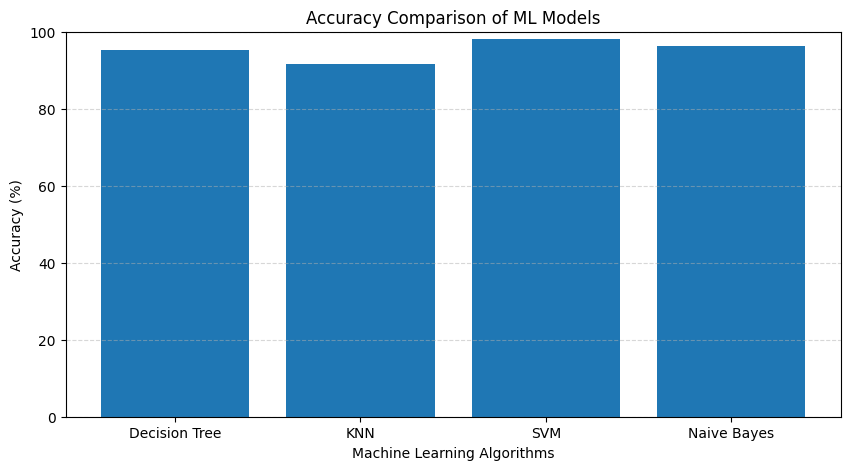

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"] * 100
)

plt.title("Accuracy Comparison of ML Models")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

In [10]:
best_model = results_df.loc[
    results_df["Accuracy"].idxmax()
]

print("BEST PERFORMING MODEL")
print("=====================")

print("Model:", best_model["Model"])

print("Accuracy:",
      round(best_model["Accuracy"] * 100, 2), "%")

print("Precision:",
      round(best_model["Precision"] * 100, 2), "%")

print("Recall:",
      round(best_model["Recall"] * 100, 2), "%")

print("F1 Score:",
      round(best_model["F1 Score"] * 100, 2), "%")

BEST PERFORMING MODEL
Model: SVM
Accuracy: 98.21 %
Precision: 97.78 %
Recall: 88.59 %
F1 Score: 92.96 %


SVM model trained successfully!
Prediction completed successfully!


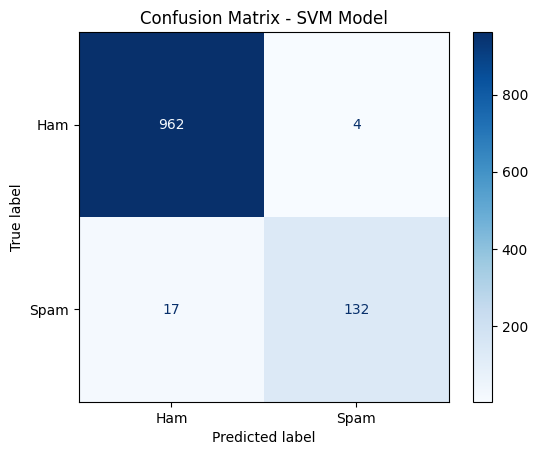

CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       966
        Spam       0.97      0.89      0.93       149

    accuracy                           0.98      1115
   macro avg       0.98      0.94      0.96      1115
weighted avg       0.98      0.98      0.98      1115



In [20]:
# Import required libraries
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

# Step 1: Create and train the SVM model
svm_model = SVC(kernel="linear")

svm_model.fit(X_train_tfidf, y_train)

print("SVM model trained successfully!")

# Step 2: Predict test data
y_pred = svm_model.predict(X_test_tfidf)

print("Prediction completed successfully!")

# Step 3: Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - SVM Model")
plt.show()

# Step 4: Classification report
print("CLASSIFICATION REPORT")
print("====================")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
))

In [21]:
# Step 5: Test new messages

messages = [
    "Congratulations! You won a free prize. Claim now!",
    "Hello, how are you? Shall we meet tomorrow?",
    "URGENT! You have won a lottery. Call now!",
    "Are you coming to college today?"
]

# Convert messages into TF-IDF
messages_tfidf = vectorizer.transform(messages)

# Predict using trained SVM model
predictions = svm_model.predict(messages_tfidf)

# Display predictions
for msg, prediction in zip(messages, predictions):

    result = "Spam" if prediction == 1 else "Ham"

    print("Message:", msg)
    print("Prediction:", result)
    print("---------------------------")

Message: Congratulations! You won a free prize. Claim now!
Prediction: Ham
---------------------------
Message: Hello, how are you? Shall we meet tomorrow?
Prediction: Ham
---------------------------
Message: URGENT! You have won a lottery. Call now!
Prediction: Ham
---------------------------
Message: Are you coming to college today?
Prediction: Ham
---------------------------


In [22]:
print("PROJECT CONCLUSION")
print("=================")

print("Spam Message Detection using Machine Learning")
print("")

print("Algorithms were compared based on performance.")
print("SVM achieved the best accuracy of 98.21%.")
print("The model classifies messages into Spam and Ham.")
print("Machine Learning helps detect unwanted messages.")
print("")
print("PROJECT COMPLETED SUCCESSFULLY!")

PROJECT CONCLUSION
Spam Message Detection using Machine Learning

Algorithms were compared based on performance.
SVM achieved the best accuracy of 98.21%.
The model classifies messages into Spam and Ham.
Machine Learning helps detect unwanted messages.

PROJECT COMPLETED SUCCESSFULLY!
